In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             ConfusionMatrixDisplay)

In [2]:
# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

In [3]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [4]:
# Preprocessing
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [5]:
# Train models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

Logistic Regression LogisticRegression(max_iter=1000)

 Logistic Regression
Accuracy: 0.9825
Precision: 0.9861
Recall: 0.9861
F1-Score: 0.9861


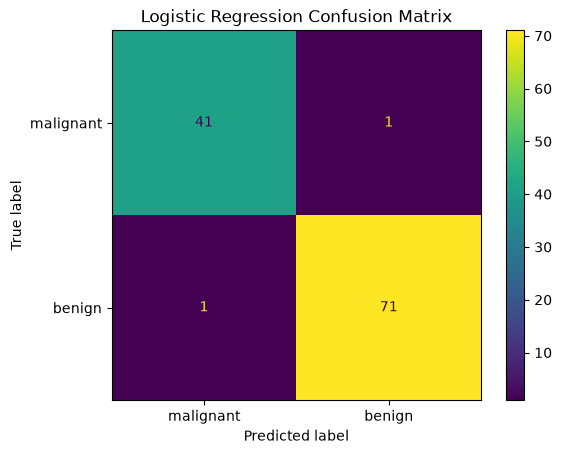

KNN KNeighborsClassifier()

 KNN
Accuracy: 0.9561
Precision: 0.9589
Recall: 0.9722
F1-Score: 0.9655


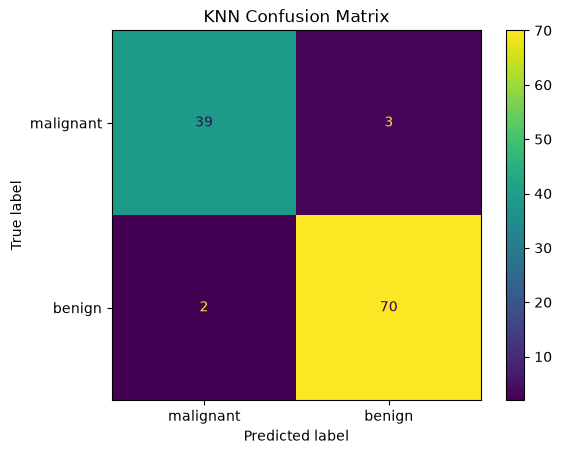

In [11]:
results = []

for name, model in models.items():
    # print(name, model)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred)
    ])

    print("\n", name)
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print("Precision:", round(precision_score(y_test, pred), 4))
    print("Recall:", round(recall_score(y_test, pred), 4))
    print("F1-Score:", round(f1_score(y_test, pred), 4))

    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=data.target_names
    )
    plt.title(name + " Confusion Matrix")
    plt.show()

In [7]:
# Compare results
df = pd.DataFrame(results, columns=[
    'Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'
])

In [10]:
print("Model Comparison:")
print(df.round(4).to_string(index=False))

Model Comparison:
              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.9825     0.9861  0.9861    0.9861
                KNN    0.9561     0.9589  0.9722    0.9655


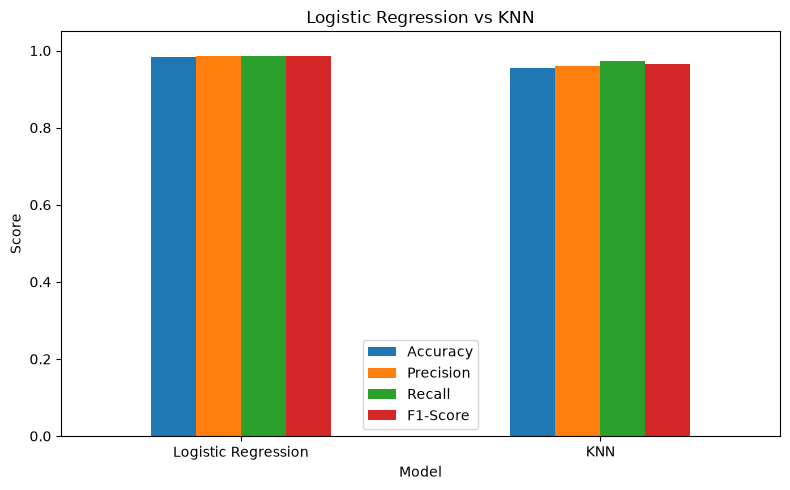

In [9]:
# Comparison graph
df.set_index('Model').plot(kind='bar', figsize=(8, 5))
plt.title('Logistic Regression vs KNN')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()